# ELECTROMAGNETIC WAVE WITH PSEUDOPSECTRAL METHOD OF LINES

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
from matplotlib.animation import PillowWriter
from mpl_toolkits.mplot3d import Axes3D

Solve the wave equation

$$ (- \partial^2_t + \partial^2_z)A^x = 0, \quad 0<=t<=4 \pi, \quad -1<=z<=1$$

with the boundary conditions

$$ A^x(t,z=-1) = A^{0x}cos(-1-t), \quad A^x(t,z=+1) = A^{0x}cos(1-t)$$

and the initial conditions

$$ A^x(t,z) = A^{0x}cos(z), \quad \partial_t A^x(0,x) = A^{0x}sin(z)$$

The full analytical solution is 

$$ A^x = A^{0x} cos(z-t)$$

Solve the wave equation

$$ (- \partial^2_t + \partial^2_z)A^y = 0, \quad 0<=t<=4 \pi, \quad -1<=z<=1$$

with the boundary conditions

$$ A^y(t,z=-1) = -A^{0x}sin(-1-t), \quad A^x(t,z=+1) = -A^{0x}sin(1-t)$$

and the initial conditions

$$ A^y(t,z) = -A^{0x}sin(z), \quad \partial_t A^y(0,x) = A^{0x}cos(z)$$

The full analytical solution is 

$$ A^y = -A^{0x} sin(z-t)$$

## Spectral Helpers

In [2]:
n = 50

diff = np.loadtxt('diffmatrix100.txt')[0:n,0:n]

chebyshevs = []
for i in range(0, n):
    chebyshevs.append(scipy.special.chebyt(i))

In [3]:
def calc_T_matrix(dim, xcol):
    T = np.zeros(dim)
    for i in range(0,dim):
        T[i] = chebyshevs[i](xcol)
    return T

#Gauss-Lobatto Nodes

xouterleftcol = np.cos(np.pi*np.linspace(1,n-1, int(n-2/1 + 1))/(n- 1))
xinnercol = np.cos(np.pi*np.linspace(1, n-2, int(n-3/1 + 1))/(n-1))
xouterrightcol = np.cos(np.pi*np.linspace(0, n-2, int(n-2/1 + 1))/(n-1))

#the full collocation array
xcol = np.cos(np.pi*np.linspace(0,n-1,n)/(n- 1))

#for plotting
xplot = np.linspace(-1,1,101)

def calc_T():
    Tcol = np.zeros((len(xcol),n))
    Tplot = np.zeros((len(xplot),n))
    Touterleftcol = np.zeros((len(xouterleftcol),n))
    Tinnercol = np.zeros((len(xinnercol),n))
    Touterrightcol = np.zeros((len(xouterrightcol),n))
    for i in range(0, len(xplot)):
        Tplot[i,:] =calc_T_matrix(n, xplot[i])
    for i in range(0, len(xcol)):
        Tcol[i,:] =calc_T_matrix(n, xcol[i])
    for i in range(0, len(xouterleftcol)):
        Touterleftcol[i,:] = calc_T_matrix(n, xouterleftcol[i])
    for i in range(0, len(xinnercol)):
        Tinnercol[i,:] = calc_T_matrix(n, xinnercol[i])
    for i in range(0, len(xouterrightcol)):
        Touterrightcol[i,:] = calc_T_matrix(n, xouterrightcol[i])
    return Tcol, Tplot, Touterleftcol, Tinnercol, Touterrightcol

Tcol, Tplot, Touterleftcol, Tinnercol, Touterrightcol = calc_T()
Tdiffplot = Tplot@diff
Tdiff2plot = Tdiffplot@diff

Tdiffouterleftcol = np.matmul(Touterleftcol, diff)
Tdiff2outerleftcol = np.matmul(np.matmul(Touterleftcol, diff), diff)
Tdiffinnercol = np.matmul(Tinnercol, diff)
Tdiff2innercol = np.matmul(np.matmul(Tinnercol, diff), diff)
Tdiffouterrightcol = np.matmul(Touterrightcol, diff)
Tdiff2outerrightcol = np.matmul(np.matmul(Touterrightcol, diff), diff)

TL = calc_T_matrix(n, -1.)
TR = calc_T_matrix(n, +1.)

## Match to Initial Condition

In [4]:
#analytical
k = 10.
w = k #this keeps c=1

A0x = 1.

Ax_ana_sol = lambda t,z: A0x*np.cos(k*z - w*t)

Ax_ana_sol_t = lambda t,z: w*A0x*np.sin(k*z - w*t)

Ay_ana_sol = lambda t,z: -A0x*np.sin(k*z-w*t)

Ay_ana_sol_t = lambda t,z: w*A0x*np.cos(k*z-w*t)

In [5]:
def get_coeff(f):

    c = np.linalg.solve(Tcol, f(0.,xcol))
    return c

In [6]:

Ax_c_ID = get_coeff(Ax_ana_sol)
Ax_ct_ID = get_coeff(Ax_ana_sol_t)

Ay_c_ID = get_coeff(Ay_ana_sol)
Ay_ct_ID = get_coeff(Ay_ana_sol_t)

In [7]:
# functions to plot data

def calc_u(c):
    return Tplot@c
    
def calc_u_diff(c):
    return Tdiffplot@c

def plot_frame(c,t,f):

    plt.plot(xplot, calc_u(c), c='blue')
    plt.plot(xplot, f(t,xplot), c='red', linestyle='dashed')
       
    plt.title('Solution at t: '+str(t))
    plt.ylabel(r'$u$')
    plt.xlabel(r'$x$')
    plt.show()
    

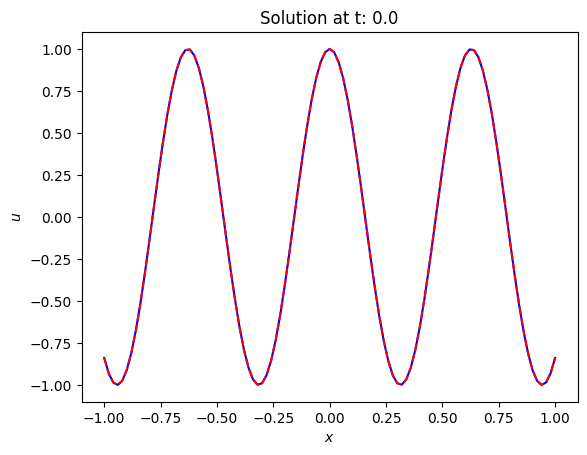

In [8]:
plot_frame(Ax_c_ID, 0., Ax_ana_sol)

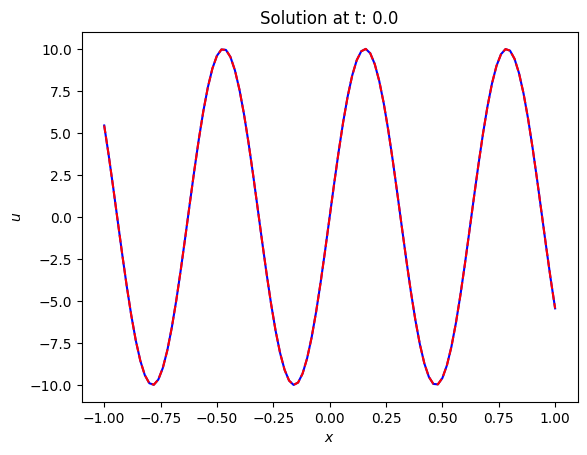

In [9]:
plot_frame(Ax_ct_ID, 0., Ax_ana_sol_t)

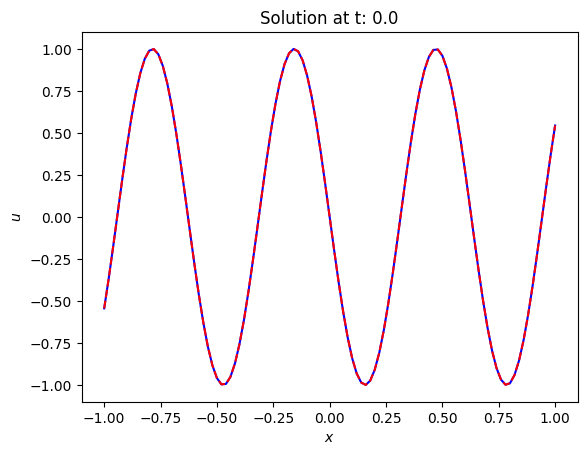

In [10]:
plot_frame(Ay_c_ID, 0., Ay_ana_sol)

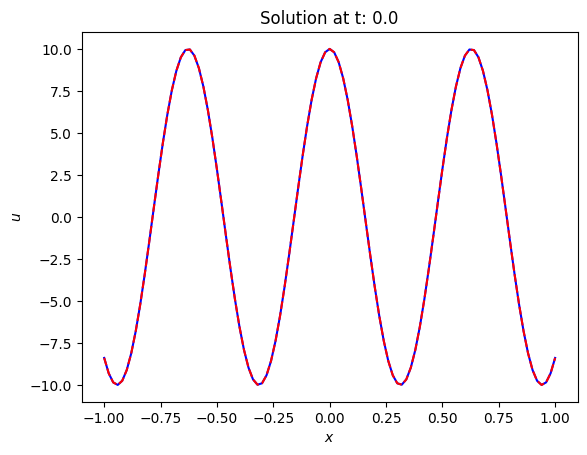

In [11]:
plot_frame(Ay_ct_ID, 0., Ay_ana_sol_t)

## Time Evolution

In [12]:
tmax = 4*np.pi
dt = 0.01*(tmax/2)
t = np.linspace(0,tmax,int(tmax/dt + 1))
dt = t[1:] -t[0:-1]

Ax_c = np.zeros((len(t),n))
Ax_ct = np.zeros((len(t),n))
Ax_ctt = np.zeros((len(t),n))

Ax_c[0,:] = Ax_c_ID
Ax_ct[0,:] = Ax_ct_ID

Ay_c = np.zeros((len(t),n))
Ay_ct = np.zeros((len(t),n))
Ay_ctt = np.zeros((len(t),n))

Ay_c[0,:] = Ay_c_ID
Ay_ct[0,:] = Ay_ct_ID


In [13]:
#parameters of sdirk butcher table

c1 = 1/4
c2 = 0.
c3 = 1/2
c4 = 1.
c5 = 1.

a11 = 1/4
a21 = -1/4
a22 = 1/4
a31 = 1/8
a32 = 1/8
a33 = 1/4
a41 = -3/2
a42 = 3/4
a43 = 3/2
a44 = 1/4
a51 = 0.
a52 = 1/6
a53 = 2/3
a54 = -1/12
a55 = 1/4

b1 = 0.
b2 = 1/6
b3 = 2/3
b4 = -1/12
b5 = 1/4

In [14]:
def solve_wave_time_slice(c, ct, f, t_inp, dt_inp, K1, K2, K3, K4, key):

    dt = dt_inp

    if key == 1:
        t = t_inp + dt*c1
    elif key == 2:
        t = t_inp + dt*c2
    elif key == 3:
        t = t_inp + dt*c3
    elif key == 4:
        t = t_inp + dt*c4
    elif key == 5:
        t = t_inp + dt*c5

    #first n rows for wave equation + boundary conditions. 
    L = np.zeros((n,n))
    R = np.zeros((n,n))
    J = np.zeros(n)
    #next n rows for constraint. this will constain the full sdirk structure.
    Lbar = np.zeros((2*n, 2*n))
    Rbar = np.zeros(2*n)

    ################################################################################

    #prepare the matrices for wave equation

    L[0:n-2,:] = Tinnercol

    R[0:n-2,:] = Tdiff2innercol 


    ##################################################################################

    #boundary conditions for wave equation

    R[-2,:] = TL
    R[-1,:] = TR
    J[-2] = f(t,-1.)
    J[-1] = f(t, +1.)

    #################################################################################

    #SDIRK

    if key == 1:

        Lbar[0:n,0:n] = L
        Lbar[0:n,n:] = -R*a11*dt
        Rbar[0:n] = R@c - J

        Lbar[n:,0:n] = -a11*dt*np.eye(n)
        Lbar[n:,n:] = np.eye(n)
        Rbar[n:] = ct

        return np.linalg.solve(Lbar,Rbar)

    elif key == 2:
        Lbar[0:n,0:n] = L
        Lbar[0:n,n:] = -R*a22*dt
        Rbar[0:n] = R@c + R@K1[n:]*a21*dt - J

        Lbar[n:,0:n] = -a22*dt*np.eye(n)
        Lbar[n:,n:] = np.eye(n)
        Rbar[n:] = ct + a21*dt*K1[0:n]

        return np.linalg.solve(Lbar,Rbar)
    
    elif key == 3:
        Lbar[0:n,0:n] = L
        Lbar[0:n,n:] = -R*a33*dt
        Rbar[0:n] = R@c + R@K1[n:]*a31*dt + R@K2[n:]*a32*dt -J

        Lbar[n:,0:n] = -a33*dt*np.eye(n)
        Lbar[n:,n:] = np.eye(n)
        Rbar[n:] = ct + a31*dt*K1[0:n] + a32*dt*K2[0:n]

        return np.linalg.solve(Lbar,Rbar)
    
    elif key == 4:
        Lbar[0:n,0:n] = L
        Lbar[0:n,n:] = -R*a44*dt
        Rbar[0:n] = R@c + R@K1[n:]*a41*dt + R@K2[n:]*a42*dt + R@K3[n:]*a43*dt - J

        Lbar[n:,0:n] = -a44*dt*np.eye(n)
        Lbar[n:,n:] = np.eye(n)
        Rbar[n:] = ct + a41*dt*K1[0:n] + a42*dt*K2[0:n] + a43*dt*K3[0:n]

        return np.linalg.solve(Lbar,Rbar)
    
    elif key == 5:
        Lbar[0:n,0:n] = L
        Lbar[0:n,n:] = -R*a55*dt
        Rbar[0:n] = R@c + R@K1[n:]*a51*dt + R@K2[n:]*a52*dt + R@K3[n:]*a53*dt + R@K4[n:]*a54*dt - J

        Lbar[n:,0:n] = -a55*dt*np.eye(n)
        Lbar[n:,n:] = np.eye(n)
        Rbar[n:] = ct + a51*dt*K1[0:n] + a52*dt*K2[0:n] + a53*dt*K3[0:n] + a54*dt*K4[0:n]

        return np.linalg.solve(Lbar,Rbar)


   

In [15]:
for i in range(0, len(t)-1):
    K1 = solve_wave_time_slice(Ax_c[i,:], Ax_ct[i,:], Ax_ana_sol, t[i], dt[i], None, None, None, None, 1) 
    K2 = solve_wave_time_slice(Ax_c[i,:], Ax_ct[i,:], Ax_ana_sol, t[i], dt[i], K1, None, None, None, 2)
    K3 = solve_wave_time_slice(Ax_c[i,:], Ax_ct[i,:], Ax_ana_sol, t[i], dt[i], K1, K2, None, None, 3)
    K4 = solve_wave_time_slice(Ax_c[i,:], Ax_ct[i,:], Ax_ana_sol, t[i], dt[i], K1, K2, K3, None, 4)
    K5 = solve_wave_time_slice(Ax_c[i,:], Ax_ct[i,:], Ax_ana_sol, t[i], dt[i], K1, K2, K3, K4, 5)

    Ax_ctt[i+1,:] = K5[0:n] 

    Ax_ct[i+1,:] = Ax_ct[i,:] + dt[i]*(b1*K1[0:n] + b2*K2[0:n] +b3*K3[0:n] + b4*K4[0:n] + b5*K5[0:n])

    Ax_c[i+1,:] = Ax_c[i,:] + dt[i]*(b1*K1[n:] + b2*K2[n:] +b3*K3[n:] + b4*K4[n:] + b5*K5[n:])

    K1 = solve_wave_time_slice(Ay_c[i,:], Ay_ct[i,:], Ay_ana_sol, t[i], dt[i], None, None, None, None, 1) 
    K2 = solve_wave_time_slice(Ay_c[i,:], Ay_ct[i,:], Ay_ana_sol, t[i], dt[i], K1, None, None, None, 2)
    K3 = solve_wave_time_slice(Ay_c[i,:], Ay_ct[i,:], Ay_ana_sol, t[i], dt[i], K1, K2, None, None, 3)
    K4 = solve_wave_time_slice(Ay_c[i,:], Ay_ct[i,:], Ay_ana_sol, t[i], dt[i], K1, K2, K3, None, 4)
    K5 = solve_wave_time_slice(Ay_c[i,:], Ay_ct[i,:], Ay_ana_sol, t[i], dt[i], K1, K2, K3, K4, 5)

    Ay_ctt[i+1,:] = K5[0:n]

    Ay_ct[i+1,:] = Ay_ct[i,:] + dt[i]*(b1*K1[0:n] + b2*K2[0:n] +b3*K3[0:n] + b4*K4[0:n] + b5*K5[0:n])

    Ay_c[i+1,:] = Ay_c[i,:] + dt[i]*(b1*K1[n:] + b2*K2[n:] +b3*K3[n:] + b4*K4[n:] + b5*K5[n:])


## Visualize Fields

For $A = (0,A^{0x}cos(kz - \omega t),-A^{0x}sin(kz - \omega t),0)$, the felds are analytically given as,

$$ E^x = - \omega A^{0x}sin(kz-\omega t)$$

$$ E^y = - \omega A^{0x}cos(kz-\omega t)$$

$$ B^x = k A^{0x} cos(kz - \omega t)$$

$$ B^y = -k A^{0x} sin(kz - \omega t)$$

$\vec{B} = k \vec{A}$ ($\vec{A}$ is an eigenvector of the curl operator because it is a circularly-polarized gauge vector) and $\vec{E}\cdot \vec{B} = 0$

In [20]:
def plot_gauge_field_frame(index, ax):
    ax.plot(calc_u(Ax_c[index,:]), calc_u(Ay_c[index,:]), xplot , label =r'$\vec{A}$')
    ax.plot(A0x*np.cos(k*xplot - w*t[index]), -A0x*np.sin(k*xplot - w*t[index]) , xplot, linestyle='dashed', c='white', label ='analytical solutions')

    
def plot_electric_field_frame(index, ax):
    ax.plot(calc_u(-Ax_ct[index,:]), calc_u(-Ay_ct[index,:]), xplot, label =r'$\vec{E}$' )
    ax.plot(-w*A0x*np.sin(k*xplot - w*t[index]), -w*A0x*np.cos(k*xplot - w*t[index]) ,xplot, linestyle='dashed', c='white')

def plot_magnetic_field_frame(index, ax): #this is equal to the gauge field!
    ax.plot(calc_u_diff(-Ay_c[index,:]), calc_u_diff(Ax_c[index,:]), xplot , label =r'$\vec{B}$')
    ax.plot(k*A0x*np.cos(k*xplot - w*t[index]), -k*A0x*np.sin(k*xplot - w*t[index]) ,xplot, linestyle='dashed', c='white')


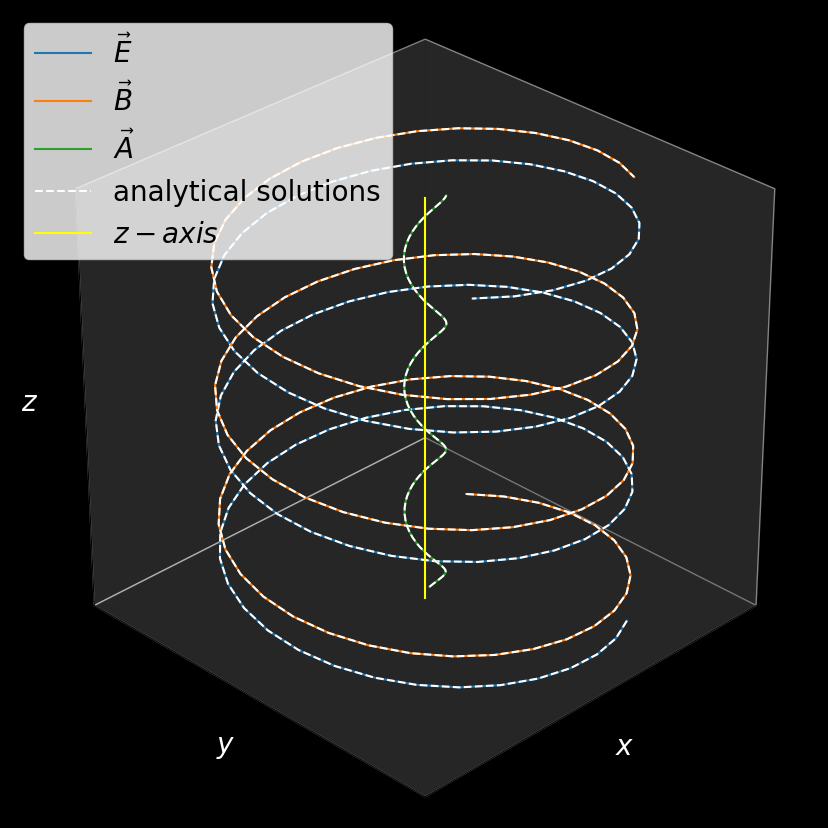

In [27]:
fig = plt.figure()
fig.patch.set_facecolor('black')


fig.set_size_inches(18.5, 10.5, forward=True)
gauge_fields = plt.subplot(1,1,1, projection='3d')

plot_electric_field_frame(0, gauge_fields)
plot_magnetic_field_frame(0, gauge_fields)
plot_gauge_field_frame(0, gauge_fields)

gauge_fields.plot(np.zeros(len(xplot)), np.zeros(len(xplot)), xplot, c='yellow', label =r'$z-axis$')
gauge_fields.legend(fontsize = 20, loc=2)
gauge_fields.view_init(elev=30, azim=45)
gauge_fields.set_box_aspect([1,1,1])
#gauge_fields.set_axis_off()
gauge_fields.set_xticks([])
gauge_fields.set_yticks([])
gauge_fields.set_zticks([])
gauge_fields.set_facecolor('black')
gauge_fields.set_xlabel(r'$x$', c='white', fontsize=20)
gauge_fields.set_ylabel(r'$y$', c='white', fontsize=20)
gauge_fields.set_zlabel(r'$z$', c='white', fontsize=20)
gauge_fields.xaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))
gauge_fields.yaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))
gauge_fields.zaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))

plt.show()

In [28]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

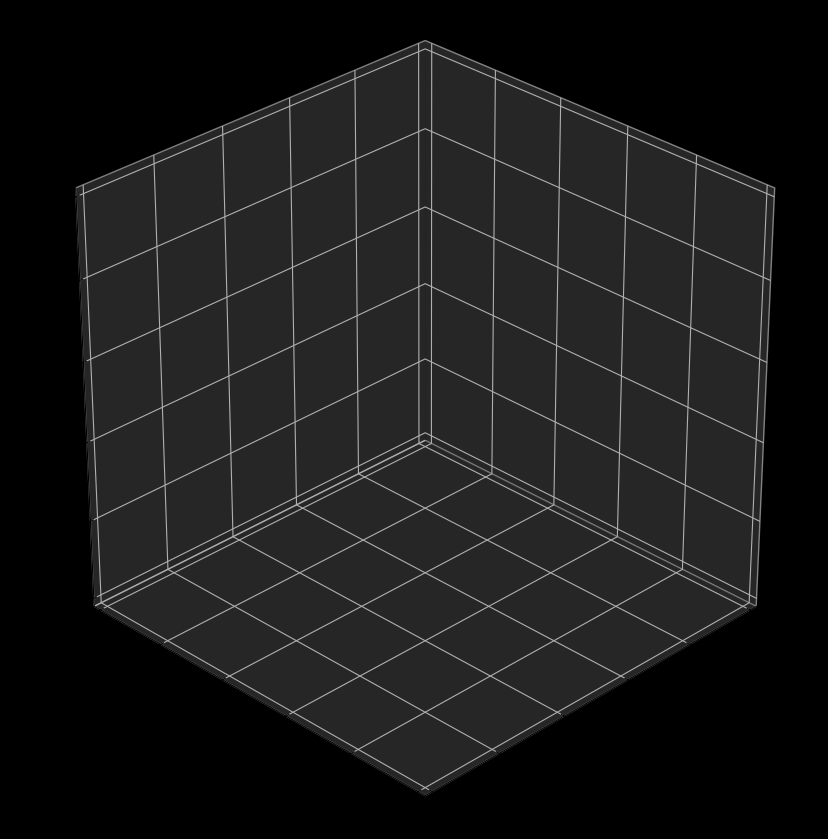

In [29]:
fig = plt.figure()
fig.patch.set_facecolor('black')
fig.set_size_inches(18.5, 10.5, forward=True)
gauge_fields = plt.subplot(1,1,1, projection='3d')


with writer.saving(fig, 'electrodynamics.gif',100):
    for i in range(0, len(t)):
        if i%1 == 0:
        
            plot_electric_field_frame(i, gauge_fields)
            plot_magnetic_field_frame(i, gauge_fields)
            plot_gauge_field_frame(i, gauge_fields)
            gauge_fields.plot(np.zeros(len(xplot)), np.zeros(len(xplot)), xplot, c='yellow', label =r'$z-axis$')
            
            gauge_fields.set_xlim([-10.1,10.1])
            gauge_fields.set_ylim([-10.1,10.1])
            gauge_fields.set_zlim([-1.1,1.1])
            if i<50:
                gauge_fields.view_init(elev=0, azim=0)
            elif 50<=i<125:
                gauge_fields.view_init(elev=0, azim=0.6*i-30)
            elif 125<=i<200:
                gauge_fields.view_init(elev=0.4*i-50, azim=45)
            gauge_fields.set_box_aspect([1,1,1])
            gauge_fields.set_xticks([])
            gauge_fields.set_yticks([])
            gauge_fields.set_zticks([])
            gauge_fields.set_facecolor('black')
            gauge_fields.set_xlabel(r'$x$', c='white', fontsize=20)
            gauge_fields.set_ylabel(r'$y$', c='white', fontsize=20)
            gauge_fields.set_zlabel(r'$z$', c='white', fontsize=20)
            gauge_fields.xaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))
            gauge_fields.yaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))
            gauge_fields.zaxis.pane.set_facecolor((0.3, 0.3, 0.3, 1))
            gauge_fields.legend(fontsize = 20, loc=2)
            #gauge_fields.set_axis_off()
            writer.grab_frame()
            gauge_fields.clear()

## Gauge Condition

The gauge condition is trivially true because $A =(0, A^x(t,z), A^y(t,z),0)$ and $\partial_\mu A^\mu = 0$

## Check Maxwell's Laws

$ \nabla \cdot \vec{E} = 0, \quad \nabla \cdot \vec{B} = 0 $ are trivially true

$$ \nabla \times \vec{E} = - \partial_t \vec{B} = \left( -w k A^{0x}sin(kz - wt), -wk A^{0x}cos(kz-wt),0\right)$$

$$ \nabla \times \vec{B} = \partial_t \vec{E} = \left( w^2 A^{0x}cos(kz - wt), -w^2 A^{0x}sin(kz-wt),0\right) = \left( k^2 A^{0x}cos(kz - wt), -k^2 A^{0x}sin(kz-wt),0\right), \quad (w=k)$$

Using spectral expansions (analytically), it is trivial to show that the above two are always true. In fact, the second homogeneous equation just reduces to the wave equation which is what we solved numerically.

## Check Conservation Laws

$$ U = \frac{1}{2}(E^2 + B^2) = \omega^2 (A^{0x})^2$$

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_27148\503276294.py:12: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(np.abs(1-energy_density_num/energy_density_ana)))


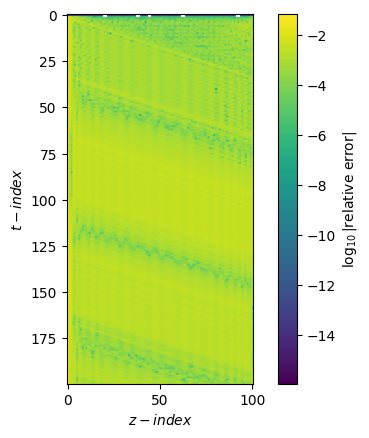

In [37]:
def check_energy_density_error():
    energy_density_ana = w**2*A0x**2

    energy_density_num = np.zeros((len(t),len(xplot)))
    for i in range(0, len(t)):
        Ex = calc_u(-Ax_ct[i,:])
        Ey = calc_u(-Ay_ct[i,:])
        Bx = calc_u_diff(-Ay_c[i,:])
        By = calc_u_diff(Ax_c[i,:])
        energy_density_num[i,:] = (1/2)*(Ex**2 + Ey**2 +Bx**2 + By**2) 
    
    plt.imshow(np.log10(np.abs(1-energy_density_num/energy_density_ana)))
    plt.xlabel(r'$z-index$')
    plt.ylabel(r'$t-index$')
    plt.colorbar(label =r'$\log_{10}|\text{relative error}|$')
    plt.show()

check_energy_density_error()
    


$$ \vec{S} = \vec{E} \times \vec{B} = \left(0,0,2 wk (A^{0x})^2 \right)$$

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_27148\625085780.py:12: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(np.abs(1-momentum_density_num/momentum_density_ana)))


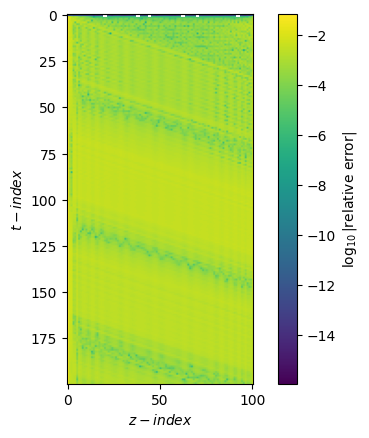

In [43]:
def check_momentum_density_error():
    momentum_density_ana = w*k*A0x**2

    momentum_density_num = np.zeros((len(t),len(xplot)))
    for i in range(0, len(t)):
        Ex = calc_u(-Ax_ct[i,:])
        Ey = calc_u(-Ay_ct[i,:])
        Bx = calc_u_diff(-Ay_c[i,:])
        By = calc_u_diff(Ax_c[i,:])
        momentum_density_num[i,:] = (Ex*By - Ey*Bx) 

    plt.imshow(np.log10(np.abs(1-momentum_density_num/momentum_density_ana)))
    plt.xlabel(r'$z-index$')
    plt.ylabel(r'$t-index$')
    plt.colorbar(label =r'$\log_{10}|\text{relative error}|$')
    plt.show()

check_momentum_density_error()